In [1]:
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
# Loading the model
BASE_DIR = Path("..")

# Load test data
X_test = pd.read_csv(BASE_DIR / "data/processed/X_test.csv")
y_test = pd.read_csv(BASE_DIR / "data/processed/y_test.csv").squeeze("columns")

# Load final model and label encoder
model = joblib.load(BASE_DIR / "models/final_xgboost_model.joblib")
label_encoder = joblib.load(BASE_DIR / "data/processed/label_encoder.joblib")

# Create reports directory if needed
reports_dir = BASE_DIR / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)
print("Model and label encoder loaded successfully.")

Test features: (20000, 174)
Test labels: (20000,)
Model and label encoder loaded successfully.


In [4]:
# Calculating Evalutation metrics
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

weighted_precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
weighted_recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
weighted_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

metrics = pd.DataFrame([{
    "accuracy": accuracy,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_precision,
    "weighted_recall": weighted_recall,
    "weighted_f1": weighted_f1
}])

display(metrics.round(4))

metrics.to_csv(
    reports_dir / "final_xgboost_metrics.csv",
    index=False
)

print("Metrics saved to reports/final_xgboost_metrics.csv")

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,0.6722,0.398,0.3108,0.3393,0.6681,0.6722,0.6647


Metrics saved to reports/final_xgboost_metrics.csv


In [7]:
# Generating the Classification Report
class_names = label_encoder.classes_

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

report_df.to_csv(
    reports_dir / "final_xgboost_classification_report.csv"
)

print("Classification report saved successfully.")

,precision,recall,f1-score,support
Acute_Gastroenteritis,0.0000,0.0000,0.0000,1.0000
Amyotrophic_Lateral_Sclerosis,0.4000,0.2000,0.2667,10.0000
Asthma,0.6853,0.8441,0.7564,4259.0000
COPD,0.6520,0.5049,0.5691,412.0000
COVID19,0.5979,0.4201,0.4935,407.0000
Chronic_Kidney_Disease,0.6784,0.6356,0.6563,999.0000
Chronic_Liver_Disease,0.0000,0.0000,0.0000,1.0000
Cirrhosis,0.0000,0.0000,0.0000,4.0000
Common_Cold,0.7110,0.4899,0.5801,447.0000
Coronary_Artery_Disease,0.6975,0.4511,0.5479,184.0000


Classification report saved successfully.


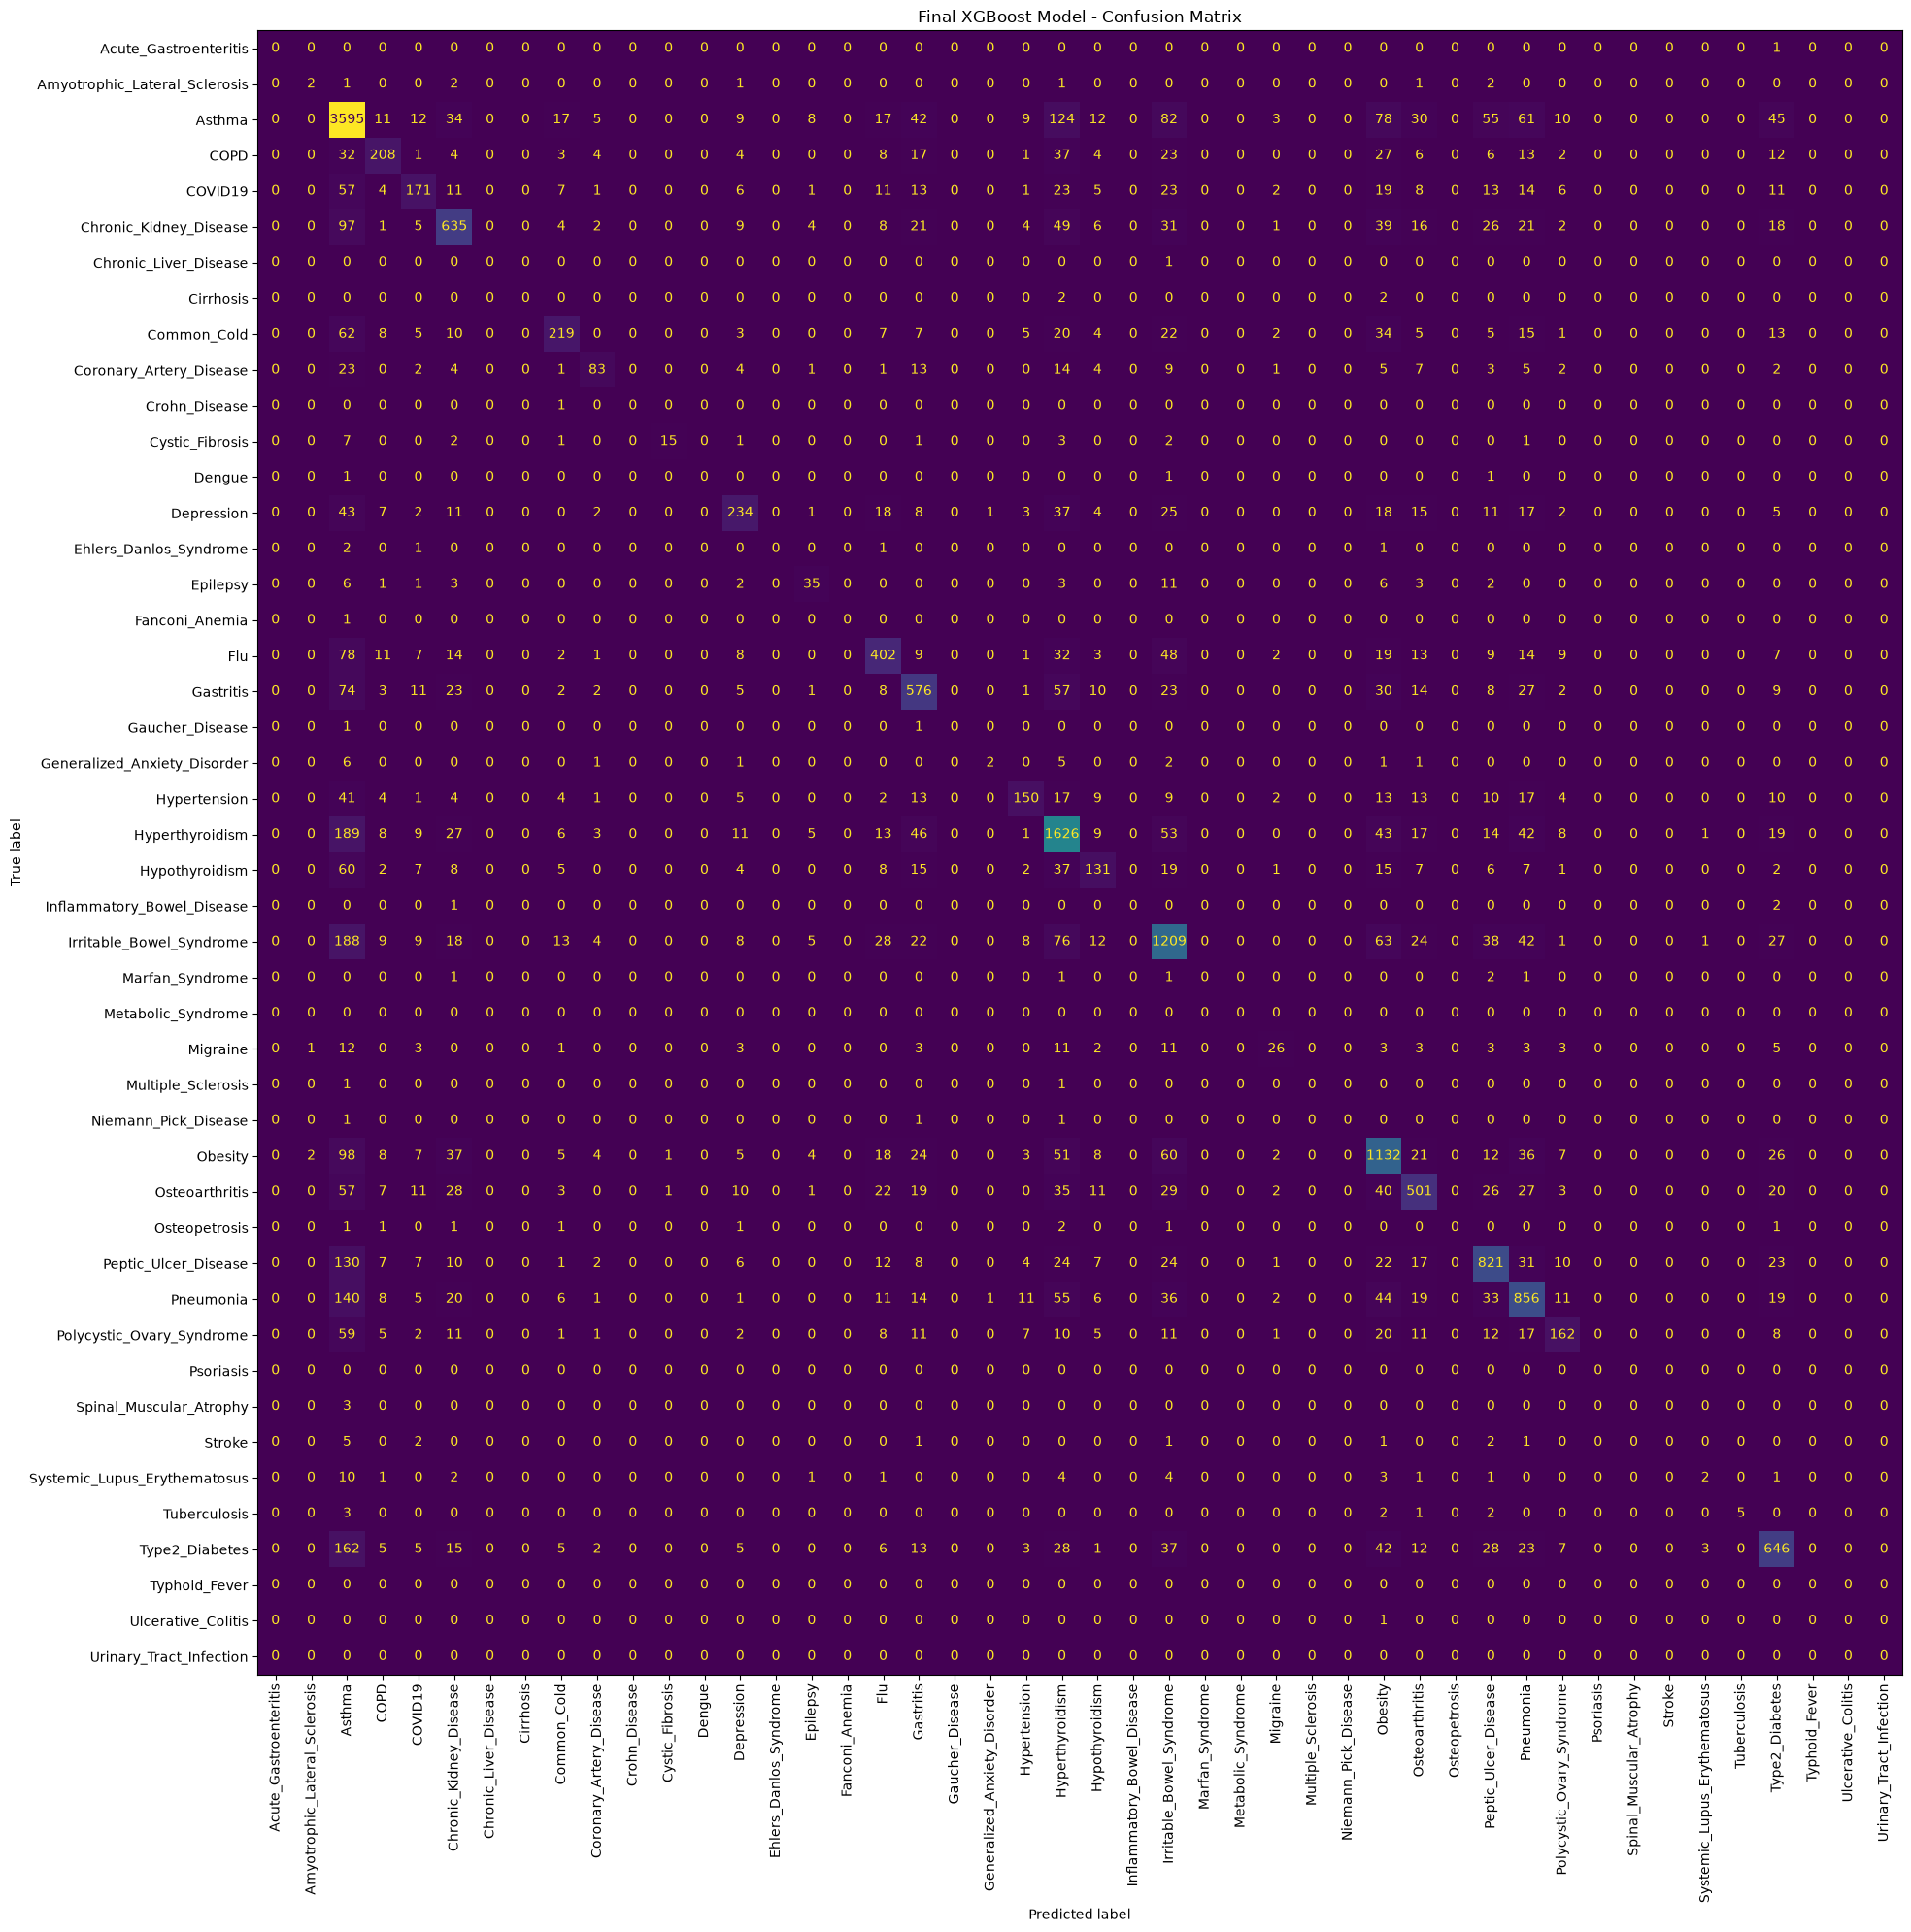

Confusion matrix saved successfully.


In [6]:
# Plotting the Confusion Matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get disease names from the saved LabelEncoder
class_names = label_encoder.classes_

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(22, 20))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Final XGBoost Model - Confusion Matrix")
plt.tight_layout()

# Save the figure
plt.savefig(
    reports_dir / "final_xgboost_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully.")